# E02-DB — DBSCAN

Cấu hình: RFM + AOV + Diversity → winsorization P99 (F, M, AOV, Diversity; R giữ nguyên) → lọc tương quan |Spearman| > 0.85 (trên feature đã cap, trước log) → log1p → StandardScaler → PCA 90%.

## Params

In [1]:
FEATURES = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity']
RANDOM_STATE = 42
CAP_Q = 99
CORR_THR = 0.85
PRIORITY = ['Recency', 'Frequency', 'Monetary', 'Diversity', 'AOV']
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]
EPS_GRID = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]
MAX_NOISE = 0.05
MIN_CLUSTERS = 2

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

RENAME = {"avg_order_value": "AOV", "n_stock_codes": "Diversity"}
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns=RENAME)
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)
X_ALL = X.copy()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4,327 khách, 5 feature (Recency, Frequency, Monetary, AOV, Diversity), không thiếu giá trị và không có giá trị âm. Monetary lệch phải rất mạnh (trung vị 657.9, lớn nhất 278,748), nên winsorization và `log1p` ảnh hưởng nhiều đến kết quả.

## Winsorization ở cấp khách (không xóa khách)

In [3]:
caps = X.quantile(CAP_Q / 100)
caps["Recency"] = np.inf
capped = X.gt(caps, axis=1)
cap_report = pd.DataFrame({
    "cap": caps.replace(np.inf, np.nan).round(2),
    "customers_capped": capped.sum(),
    "customers_capped_pct": (100 * capped.mean()).round(2),
    "value_capped_pct": (100 * (X - X.clip(upper=caps, axis=1)).sum() / X.sum()).round(2),
})
print(f"Khách bị cap ở ít nhất 1 biến: {int(capped.any(axis=1).sum())} ({100 * capped.any(axis=1).mean():.2f}%) | không xóa khách nào")
cap_report

Khách bị cap ở ít nhất 1 biến: 116 (2.68%) | không xóa khách nào


,cap,customers_capped,customers_capped_pct,value_capped_pct
Recency,NaN,0,0.00,0.00
Frequency,30.00,42,0.97,6.12
Monetary,17279.06,44,1.02,21.62
AOV,1894.54,44,1.02,4.45
Diversity,353.74,44,1.02,3.50


**Nhận xét:** Cap ở phân vị 99: 116 khách (2.68%) bị cap ở ít nhất một biến; không xóa khách nào, Recency giữ nguyên. Monetary bị cắt nhiều giá trị nhất: 44 khách (1.02%) nhưng chiếm 21.62% tổng Monetary.

## Lọc tương quan (Spearman, trên feature đã cap, trước log)

In [4]:
def correlation_filter(Xc, thr):
    rho = Xc.corr(method="spearman").abs()
    dropped = []
    pairs = sorted(((rho.loc[a, b], a, b) for i, a in enumerate(Xc.columns) for b in Xc.columns[i + 1:]), reverse=True)
    for r, a, b in pairs:
        if r <= thr:
            break
        if a in dropped or b in dropped:
            continue
        dropped.append(max((a, b), key=PRIORITY.index))
    return dropped

Xc = X.clip(upper=caps, axis=1)
rho = Xc.corr(method="spearman")
dropped = correlation_filter(Xc, CORR_THR)
off = rho.abs().where(~np.eye(len(rho), dtype=bool))
print(f"|Spearman| lớn nhất giữa hai biến: {off.max().max():.4f}")
print("Biến bị loại:", dropped if dropped else "không có")
if not dropped:
    print(f"Không loại biến nào ở ngưỡng {CORR_THR}: cùng tập feature với D01")
FEATURES = [f for f in FEATURES if f not in dropped]
X, caps = X_ALL[FEATURES], caps[FEATURES]
print("Feature đưa vào mô hình:", FEATURES)
rho.round(3)

|Spearman| lớn nhất giữa hai biến: 0.8094
Biến bị loại: không có
Không loại biến nào ở ngưỡng 0.85: cùng tập feature với D01
Feature đưa vào mô hình: ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity']


,Recency,Frequency,Monetary,AOV,Diversity
Recency,1.000,-0.564,-0.485,-0.132,-0.456
Frequency,-0.564,1.000,0.809,0.162,0.655
Monetary,-0.485,0.809,1.000,0.679,0.732
AOV,-0.132,0.162,0.679,1.000,0.423
Diversity,-0.456,0.655,0.732,0.423,1.000


**Nhận xét:** |Spearman| lớn nhất là 0.8094 (cặp Frequency–Monetary), tính trên feature đã cap, trước `log1p`. Thấp hơn ngưỡng 0.85 nên không loại biến nào: tập feature giống D01, thí nghiệm này **tương đương D01** về đầu vào.

## Tiền xử lý

In [5]:
prep = Pipeline([
    ("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps.values})),
    ("log1p", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))

Kích thước đầu vào mô hình: (4327, 3)
Phương sai từng PC: [0.6237 0.2025 0.0979] | giữ lại: 0.9241


**Nhận xét:** Đầu vào mô hình có 3 chiều (PCA giữ 92.41% phương sai; PC1 62.37%).

## Quét lưới eps × min_samples

In [6]:
rows = []
for ms in MIN_SAMPLES_GRID:
    for eps in EPS_GRID:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
        core = lab != -1
        sizes = np.bincount(lab[core]) if core.any() else np.array([0])
        ncl = len(sizes) if core.any() else 0
        ok = ncl >= 2
        rows.append({"min_samples": ms, "eps": eps, "n_clusters": ncl, "noise_pct": round(100 * (~core).mean(), 2),
                     "largest_pct": round(100 * sizes.max() / len(lab), 2), "smallest": int(sizes.min()),
                     "silhouette": silhouette_score(Z[core], lab[core]) if ok else np.nan,
                     "dbi": davies_bouldin_score(Z[core], lab[core]) if ok else np.nan})
res = pd.DataFrame(rows)
elig = res[(res["n_clusters"] >= MIN_CLUSTERS) & (res["noise_pct"] <= 100 * MAX_NOISE)]
best = elig.sort_values(["silhouette", "noise_pct"], ascending=[False, True]).iloc[0]
print(f"Đủ điều kiện: {len(elig)}/{len(res)} cấu hình")
print(f"Chọn eps={best['eps']}, min_samples={int(best['min_samples'])}: {int(best['n_clusters'])} cụm, nhiễu {best['noise_pct']}%, "
      f"Silhouette (không tính nhiễu)={best['silhouette']:.4f}, DBI={best['dbi']:.4f}")
elig.sort_values("silhouette", ascending=False).head(8).round(4)

Đủ điều kiện: 3/72 cấu hình
Chọn eps=0.5, min_samples=6: 3 cụm, nhiễu 3.42%, Silhouette (không tính nhiễu)=0.1351, DBI=0.5919


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
19,6,0.5,3,3.42,96.42,3,0.1351,0.5919
7,4,0.5,4,2.06,97.64,2,-0.0117,0.6467
6,4,0.4,10,4.78,94.31,3,-0.0944,0.6401


**Nhận xét:** Chỉ 3/72 cấu hình đủ điều kiện (nhiễu ≤ 5%, ≥ 2 cụm), nên lựa chọn dựa trên rất ít cấu hình. Cấu hình chọn có 3 cụm, nhiễu 3.42%, cụm lớn nhất chiếm 96.42% khách, cụm nhỏ nhất 3 khách. Silhouette/DBI chỉ tính trên khách không bị coi là nhiễu.

## Fit DBSCAN cuối và đồ thị k-distance

Số khách mỗi cụm (-1 = nhiễu): {-1: 148, 0: 4172, 1: 3, 2: 4}


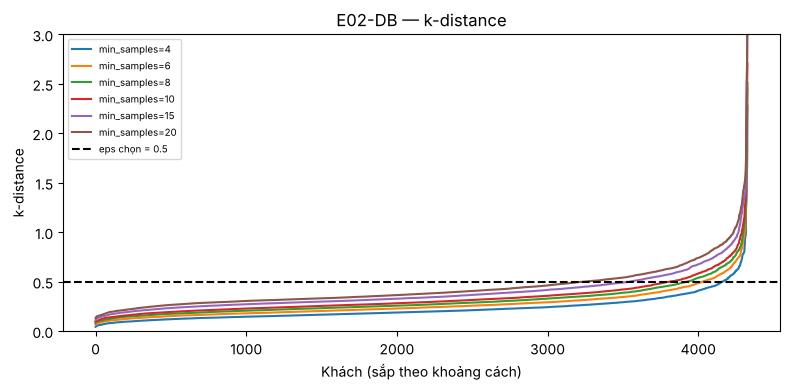

In [7]:
dbs = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"])).fit(Z)
labels = dbs.labels_
core = labels != -1
print("Số khách mỗi cụm (-1 = nhiễu):", {int(k): int(v) for k, v in zip(*np.unique(labels, return_counts=True))})

fig, ax = plt.subplots(figsize=(8, 4))
for ms in MIN_SAMPLES_GRID:
    d = NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1]
    ax.plot(np.sort(d), label=f"min_samples={ms}")
ax.axhline(float(best["eps"]), color="black", ls="--", label=f"eps chọn = {best['eps']}")
ax.set_ylim(0, 3); ax.set_xlabel("Khách (sắp theo khoảng cách)"); ax.set_ylabel("k-distance"); ax.legend(fontsize=7)
ax.set_title("E02-DB — k-distance"); plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

## Hồ sơ cụm

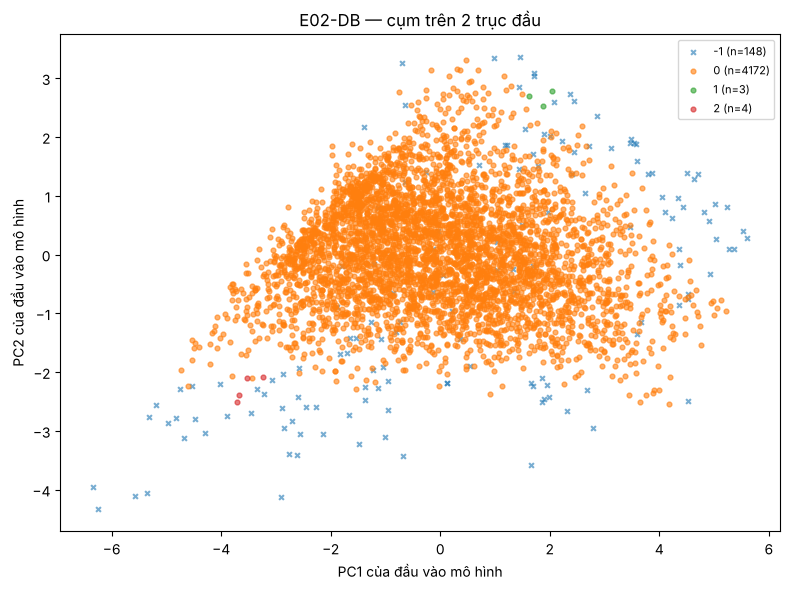

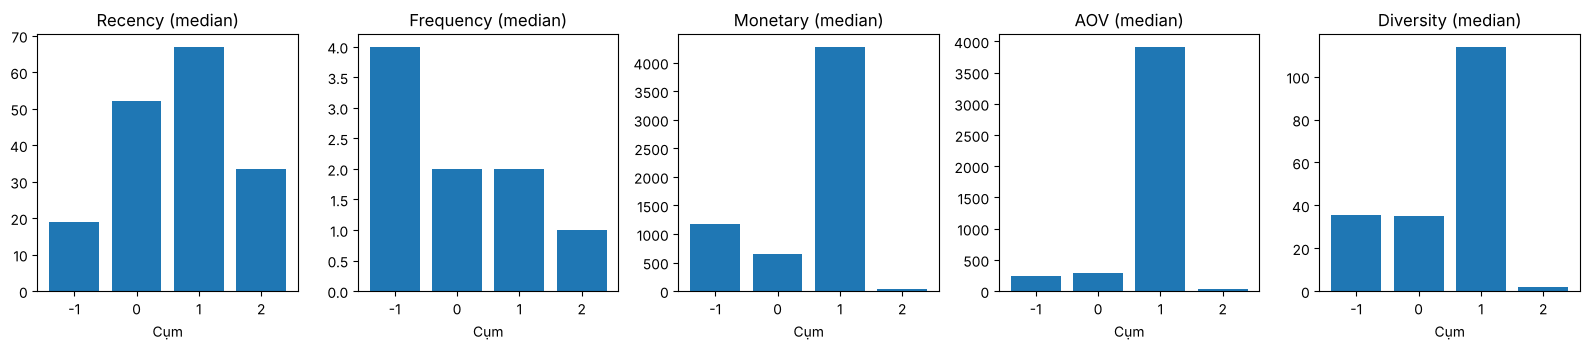

,customers,Recency,Frequency,Monetary,AOV,Diversity,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,
-1,148,19.0,4.0,1167.0,241.9,35.5,3.4,24.9
0,4172,52.0,2.0,656.0,286.9,35.0,96.4,75.0
1,3,67.0,2.0,4279.7,3914.9,114.0,0.1,0.2
2,4,33.5,1.0,39.4,39.4,2.0,0.1,0.0


In [8]:
agg = {f: (f, "median") for f in FEATURES}
prof = X.assign(cluster=labels).groupby("cluster").agg(customers=("Monetary", "size"), Monetary_sum=("Monetary", "sum"), **agg)
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("E02-DB — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, len(FEATURES), figsize=(3.2 * len(FEATURES), 3.6))
for ax, f in zip(axes, FEATURES):
    ax.bar(prof.index.astype(str), prof[f]); ax.set_title(f + " (median)"); ax.set_xlabel("Cụm")
plt.tight_layout(); plt.savefig(FIG / "feature_comparison.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 1 có Monetary trung vị cao nhất (4,280), gồm 3 khách (0.1%) nhưng chiếm 0.2% tổng Monetary. Cụm 0 đông nhất (96.4% khách, Recency trung vị 52 ngày). Nhóm nhiễu (-1) có 148 khách, chiếm 24.9% tổng Monetary. Một cụm chiếm ≥ 90% khách, nên kết quả chỉ phân biệt nhóm ngoại lai với số đông, chưa phải phân khúc khách hàng chi tiết.

## So với E01 và D01 (cùng tham số model)

In [9]:
PARENTS = {
    "E01": (99, 0.9, "std", 0.9),
    "D01": (99, None, "std", 0.9),
}

def build_parent(q, thr, scaler, pca):
    caps_p = X_ALL.quantile(q / 100)
    caps_p["Recency"] = np.inf
    feats = list(X_ALL.columns)
    if thr is not None:
        feats = [f for f in feats if f not in correlation_filter(X_ALL.clip(upper=caps_p, axis=1), thr)]
    steps = [("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps_p[feats].values})),
             ("log1p", FunctionTransformer(np.log1p)),
             ("scaler", StandardScaler() if scaler == "std" else RobustScaler(quantile_range=(25.0, 75.0)))]
    if pca:
        steps.append(("pca", PCA(n_components=pca, svd_solver="full", random_state=RANDOM_STATE)))
    return feats, Pipeline(steps)

rows = []
for name, (q, thr, scaler, pca) in PARENTS.items():
    feats_p, prep_p = build_parent(q, thr, scaler, pca)
    Zp = prep_p.fit_transform(X_ALL[feats_p].values)
    lp = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"])).fit_predict(Zp)
    rows.append({"so với": name, "số feature": len(feats_p), "số chiều": Zp.shape[1],
                 "cùng tập feature": feats_p == FEATURES, "ARI": round(adjusted_rand_score(labels, lp), 4)})
parent_cmp = pd.DataFrame(rows)
parent_cmp

,so với,số feature,số chiều,cùng tập feature,ARI
0,E01,5,3,True,1.0
1,D01,5,3,True,1.0


**Nhận xét:** E02 (cùng tham số model): ARI với E01 = 1.0000 (nhãn trùng 100%: **tương đương**); ARI với D01 = 1.0000 (nhãn trùng 100%: **tương đương**).

## Lưu kết quả

In [10]:
res.to_csv(OUT / "dbscan_e02_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_e02_labels.csv", index=False)
cap_report.to_csv(OUT / "dbscan_e02_cap_report.csv")
params = {"experiment": "E02-DB", "features": FEATURES, "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "cap_percentile": CAP_Q, "caps": {k: (None if np.isinf(v) else float(v)) for k, v in caps.items()},
          "customers_capped": int(capped.any(axis=1).sum()),
          "correlation_threshold": CORR_THR, "dropped_features": dropped,
          "transform": "log1p", "scaler": "StandardScaler", "pca": 0.9,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(prep["pca"].explained_variance_ratio_.sum()),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]), "n_clusters": int(best["n_clusters"]),
          "noise_pct": float(best["noise_pct"]), "largest_pct": float(best["largest_pct"]), "smallest": int(best["smallest"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "parent_comparison": parent_cmp.to_dict("records")}
json.dump(params, open(OUT / "dbscan_e02_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_e02_cap_report.csv', 'dbscan_e02_grid.csv', 'dbscan_e02_labels.csv', 'dbscan_e02_params.json']


**Lưu ý:** DBSCAN không có `predict` cho khách mới, `labels_` chỉ áp dụng đúng 4.327 khách và đúng thứ tự khi fit, nên không lưu file model.

**Kết luận E02-DB:** DBSCAN eps=0.5, min_samples=6: 3 cụm, nhiễu 3.42%, cụm lớn nhất 96.42% khách. ARI với E01 = 1.0000. ARI với D01 = 1.0000. Silhouette giữa các cấu hình có không gian đầu vào khác nhau (số chiều, scaler) không so sánh trực tiếp được; nên dựa vào ARI và hồ sơ cụm trên thang gốc.